# Kiểm tra TLS trên dữ liệu giả lập

Dữ liệu được sinh từ một hàm đã biết, nên có thể so sánh trực tiếp kết quả với đáp án đúng. Notebook này không dùng dữ liệu thực tế.

$$f(x) = 2 + 1.5\cos\left(\frac{2\pi x}{T}\right) + 0.5\sin\left(\frac{4\pi x}{T}\right), \qquad T = 24$$

Hệ số đúng: $a_0 = 2$, $a_1 = 1.5$, $b_2 = 0.5$, các hệ số còn lại bằng 0. Số điều hòa đúng là $K = 2$.

## 1. Import thư viện

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Cài đặt TLS

In [2]:
def design_matrix(x, period, K):
    """Ma trận thiết kế với các cột [1, cos(ωx), sin(ωx), ..., cos(Kωx), sin(Kωx)]."""
    x = np.asarray(x, dtype=float).ravel()
    omega = 2 * np.pi / period
    columns = [np.ones_like(x)]
    for k in range(1, K + 1):
        columns.extend([np.cos(k * omega * x), np.sin(k * omega * x)])
    return np.column_stack(columns)


def fit_tls(x, y, period, K):
    """Ước lượng hệ số [a0, a1, b1, ..., aK, bK] bằng bình phương tối thiểu."""
    A = design_matrix(x, period, K)
    beta, _, rank, _ = np.linalg.lstsq(A, np.asarray(y, dtype=float), rcond=None)
    if rank < A.shape[1]:
        warnings.warn("Ma trận thiết kế bị thiếu hạng.")
    return beta


def coef_names(K):
    return ["a0"] + [f"{c}{k}" for k in range(1, K + 1) for c in ("a", "b")]


def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))

## 3. Thiết lập dữ liệu

- $n = 180$ điểm cách đều trên đoạn $[0, 72)$, tức đúng 3 chu kỳ và 60 điểm mỗi chu kỳ.
- Lưới mịn 1000 điểm dùng để vẽ và để đo sai số so với hàm thật.

In [3]:
T = 24.0
n = 180
x = np.linspace(0, 72, n, endpoint=False)
x_grid = np.linspace(0, 72, 1000, endpoint=False)


def f(x):
    return 2.0 + 1.5 * np.cos(2 * np.pi * x / T) + 0.5 * np.sin(4 * np.pi * x / T)


def true_beta(K):
    """Hệ số đúng theo thứ tự [a0, a1, b1, ..., aK, bK], với K >= 2."""
    beta = np.zeros(2 * K + 1)
    beta[[0, 1, 4]] = [2.0, 1.5, 0.5]
    return beta

## 4. Thực nghiệm A: không có nhiễu

Khớp với $K = 3$, nhiều hơn số điều hòa đúng. Kỳ vọng: khôi phục đúng hệ số, còn hai hệ số thừa $a_3, b_3$ bằng 0, chỉ sai khác ở mức sai số làm tròn.

In [4]:
K = 3
y_clean = f(x)
beta_clean = fit_tls(x, y_clean, T, K)
errors = np.abs(beta_clean - true_beta(K))

table_a = pd.DataFrame(
    {"Giá trị đúng": true_beta(K), "Ước lượng": beta_clean.round(10), "Sai lệch tuyệt đối": errors},
    index=coef_names(K),
)
table_a["Sai lệch tuyệt đối"] = table_a["Sai lệch tuyệt đối"].map("{:.2e}".format)
table_a

,Giá trị đúng,Ước lượng,Sai lệch tuyệt đối
a0,2.0,2.0,0.00e+00
a1,1.5,1.5,4.44e-16
b1,0.0,-0.0,8.33e-17
a2,0.0,0.0,6.66e-16
b2,0.5,0.5,1.11e-16
a3,0.0,-0.0,2.22e-16
b3,0.0,0.0,9.02e-17


Với mỗi $K$: RMSE so với dữ liệu, số điều kiện $\kappa(A)$ và phần tử ngoài đường chéo lớn nhất của $A^{\mathsf T}A/n$. Với $K = 1$, mô hình thiếu số hạng $0.5\sin(4\pi x/T)$, nên RMSE lý thuyết là $0.5/\sqrt{2} \approx 0.3536$.

In [5]:
rows = []
for K in [1, 2, 3, 5, 10, 20]:
    A = design_matrix(x, T, K)
    beta = fit_tls(x, y_clean, T, K)
    G = A.T @ A / n
    rows.append({
        "K": K,
        "RMSE": f"{rmse(y_clean, A @ beta):.3e}",
        "cond(A)": np.linalg.cond(A),
        "|cond(A) - căn 2|": f"{abs(np.linalg.cond(A) - np.sqrt(2)):.1e}",
        "Ngoài chéo lớn nhất": f"{np.abs(G - np.diag(np.diag(G))).max():.1e}",
    })
pd.DataFrame(rows).set_index("K")

,RMSE,cond(A),|cond(A) - căn 2|,Ngoài chéo lớn nhất
K,,,,
1,3.536e-01,1.414214,0.0e+00,9.7e-17
2,1.325e-15,1.414214,0.0e+00,9.7e-17
3,1.420e-15,1.414214,0.0e+00,1.2e-16
5,1.317e-15,1.414214,0.0e+00,3.0e-16
10,1.922e-15,1.414214,1.6e-15,7.9e-16
20,4.427e-15,1.414214,2.9e-15,4.2e-15


Đối chiếu nghiệm của `lstsq` với công thức tường minh $\hat a_k = \frac{2}{n}\sum y_i\cos(k\omega x_i)$, $\hat b_k = \frac{2}{n}\sum y_i\sin(k\omega x_i)$, $\hat a_0 = \frac{1}{n}\sum y_i$.

In [6]:
omega = 2 * np.pi / T
beta_closed = [y_clean.mean()]
for k in range(1, 4):
    beta_closed += [2 / n * y_clean @ np.cos(k * omega * x), 2 / n * y_clean @ np.sin(k * omega * x)]

print(f"Chênh lệch lớn nhất giữa lstsq và công thức tường minh: {np.abs(np.array(beta_closed) - beta_clean).max():.2e}")

Chênh lệch lớn nhất giữa lstsq và công thức tường minh: 7.52e-16


## 5. Thực nghiệm B: có nhiễu

Dữ liệu quan sát $y_i = f(x_i) + \varepsilon_i$, với $\varepsilon_i$ độc lập, phân phối chuẩn, trung bình 0 và độ lệch chuẩn $\sigma = 0.25$.

Độ lệch chuẩn lý thuyết của hệ số: $\sigma/\sqrt{n}$ với $a_0$ và $\sigma\sqrt{2/n}$ với các hệ số còn lại.

### 5.1. Một lần chạy với $K = 3$

In [7]:
sigma = 0.25
K = 3
rng = np.random.default_rng(42)
y_noisy = f(x) + rng.normal(0, sigma, n)
beta_noisy = fit_tls(x, y_noisy, T, K)

sd_theory = np.full(2 * K + 1, sigma * np.sqrt(2 / n))
sd_theory[0] = sigma / np.sqrt(n)
y_hat_grid = design_matrix(x_grid, T, K) @ beta_noisy

print(f"RMSE so với dữ liệu quan sát: {rmse(y_noisy, design_matrix(x, T, K) @ beta_noisy):.4f}")
print(f"RMSE so với hàm thật (lưới mịn): {rmse(f(x_grid), y_hat_grid):.4f}")
pd.DataFrame(
    {"Giá trị đúng": true_beta(K), "Ước lượng": beta_noisy, "Sai lệch": beta_noisy - true_beta(K), "ĐLC lý thuyết": sd_theory},
    index=coef_names(K),
).round(4)

RMSE so với dữ liệu quan sát: 0.2149
RMSE so với hàm thật (lưới mịn): 0.0277


,Giá trị đúng,Ước lượng,Sai lệch,ĐLC lý thuyết
a0,2.0,1.9858,-0.0142,0.0186
a1,1.5,1.5031,0.0031,0.0264
b1,0.0,0.0087,0.0087,0.0264
a2,0.0,-0.0041,-0.0041,0.0264
b2,0.5,0.4926,-0.0074,0.0264
a3,0.0,0.0260,0.0260,0.0264
b3,0.0,0.0174,0.0174,0.0264


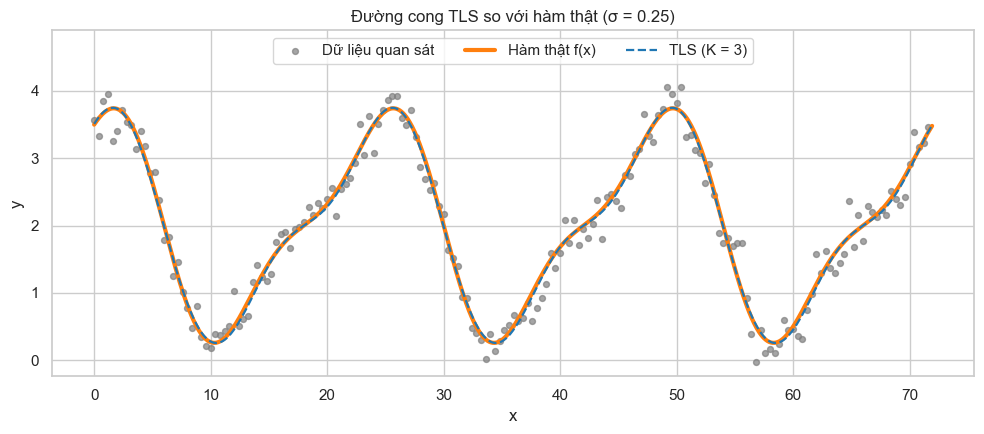

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(x, y_noisy, s=18, color="tab:gray", alpha=0.7, label="Dữ liệu quan sát")
ax.plot(x_grid, f(x_grid), lw=3, color="tab:orange", label="Hàm thật f(x)")
ax.plot(x_grid, y_hat_grid, lw=1.6, ls="--", color="tab:blue", label=f"TLS (K = {K})")
ax.set(xlabel="x", ylabel="y", title="Đường cong TLS so với hàm thật (σ = 0.25)")
ax.set_ylim(top=4.9)
ax.legend(loc="upper center", ncol=3)
fig.tight_layout()
plt.show()

### 5.2. Khảo sát số điều hòa $K$

Lặp lại 1000 lần với nhiễu mới cho mỗi $K = 1, \ldots, 20$. Sai số kiểm tra được đo trên lưới mịn với nhiễu độc lập mới. Với $K \ge 2$ và $p = 2K + 1$, giá trị lý thuyết của RMSE là: huấn luyện $\sigma\sqrt{1 - p/n}$, kiểm tra $\sigma\sqrt{1 + p/n}$, so với hàm thật $\sigma\sqrt{p/n}$.

In [9]:
REPS = 1000
rng = np.random.default_rng(43)
Y = f(x)[:, None] + rng.normal(0, sigma, (n, REPS))
Y_test = f(x_grid)[:, None] + rng.normal(0, sigma, (x_grid.size, REPS))

rows = []
for K in range(1, 21):
    B = fit_tls(x, Y, T, K)
    fitted_grid = design_matrix(x_grid, T, K) @ B
    p = 2 * K + 1
    has_truth = K >= 2
    rows.append({
        "K": K,
        "Huấn luyện": np.sqrt(np.mean((Y - design_matrix(x, T, K) @ B) ** 2)),
        "Lý thuyết huấn luyện": sigma * np.sqrt(1 - p / n) if has_truth else np.nan,
        "Kiểm tra": np.sqrt(np.mean((Y_test - fitted_grid) ** 2)),
        "Lý thuyết kiểm tra": sigma * np.sqrt(1 + p / n) if has_truth else np.nan,
        "So với f": np.sqrt(np.mean((f(x_grid)[:, None] - fitted_grid) ** 2)),
        "Lý thuyết so với f": sigma * np.sqrt(p / n) if has_truth else np.nan,
    })
sweep = pd.DataFrame(rows).set_index("K")
print("K có RMSE kiểm tra nhỏ nhất:", sweep["Kiểm tra"].idxmin())
sweep.round(4)

K có RMSE kiểm tra nhỏ nhất: 2


,Huấn luyện,Lý thuyết huấn luyện,Kiểm tra,Lý thuyết kiểm tra,So với f,Lý thuyết so với f
K,,,,,,
1,0.4310,NaN,0.4346,NaN,0.3550,NaN
2,0.2456,0.2465,0.2537,0.2534,0.0414,0.0417
3,0.2442,0.2451,0.2550,0.2548,0.0489,0.0493
4,0.2428,0.2437,0.2564,0.2562,0.0555,0.0559
5,0.2413,0.2422,0.2578,0.2575,0.0617,0.0618
6,0.2398,0.2408,0.2592,0.2589,0.0672,0.0672
7,0.2383,0.2394,0.2606,0.2602,0.0723,0.0722
8,0.2369,0.2379,0.2619,0.2615,0.0768,0.0768
9,0.2355,0.2364,0.2632,0.2629,0.0811,0.0812


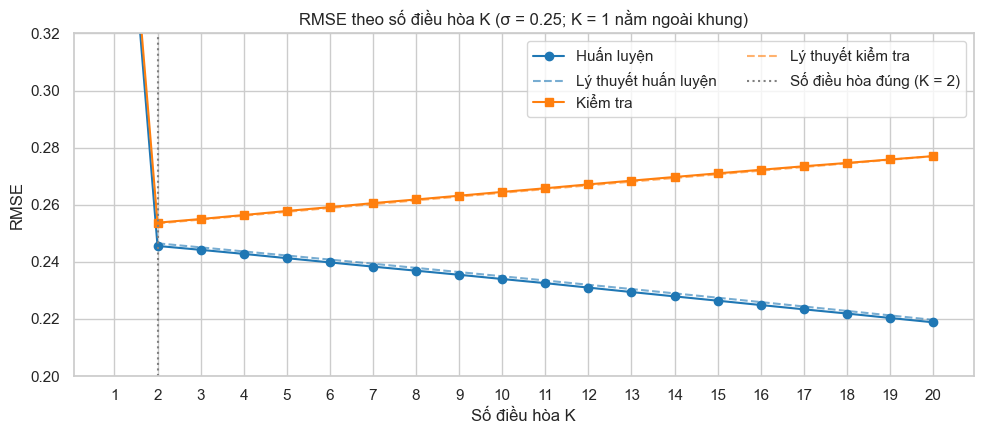

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sweep.index, sweep["Huấn luyện"], marker="o", color="tab:blue", label="Huấn luyện")
ax.plot(sweep.index, sweep["Lý thuyết huấn luyện"], ls="--", color="tab:blue", alpha=0.6, label="Lý thuyết huấn luyện")
ax.plot(sweep.index, sweep["Kiểm tra"], marker="s", color="tab:orange", label="Kiểm tra")
ax.plot(sweep.index, sweep["Lý thuyết kiểm tra"], ls="--", color="tab:orange", alpha=0.6, label="Lý thuyết kiểm tra")
ax.axvline(2, color="gray", ls=":", label="Số điều hòa đúng (K = 2)")
ax.set_ylim(0.2, 0.32)
ax.set_xticks(sweep.index)
ax.set(xlabel="Số điều hòa K", ylabel="RMSE", title="RMSE theo số điều hòa K (σ = 0.25; K = 1 nằm ngoài khung)")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

### 5.3. Ảnh hưởng của mức nhiễu

Giữ $K = 2$, thay đổi $\sigma$, mỗi mức lặp lại 1000 lần.

In [11]:
K = 2
p = 2 * K + 1
A_grid = design_matrix(x_grid, T, K)
rng = np.random.default_rng(44)

rows = []
for s in [0.05, 0.1, 0.25, 0.5, 1.0]:
    B = fit_tls(x, f(x)[:, None] + rng.normal(0, s, (n, REPS)), T, K)
    rows.append({
        "σ": s,
        "TB a1 (đúng 1.5)": B[1].mean(),
        "TB b2 (đúng 0.5)": B[4].mean(),
        "ĐLC a1": B[1].std(),
        "ĐLC lý thuyết": s * np.sqrt(2 / n),
        "RMSE so với f": np.sqrt(np.mean((f(x_grid)[:, None] - A_grid @ B) ** 2)),
        "Lý thuyết": s * np.sqrt(p / n),
    })
pd.DataFrame(rows).set_index("σ").round(4)

,TB a1 (đúng 1.5),TB b2 (đúng 0.5),ĐLC a1,ĐLC lý thuyết,RMSE so với f,Lý thuyết
σ,,,,,,
0.05,1.5001,0.5000,0.0051,0.0053,0.0083,0.0083
0.10,1.4997,0.4998,0.0104,0.0105,0.0169,0.0167
0.25,1.4997,0.5005,0.0264,0.0264,0.0418,0.0417
0.50,1.5005,0.5006,0.0531,0.0527,0.0835,0.0833
1.00,1.4988,0.4950,0.1078,0.1054,0.1692,0.1667


## 6. Kết luận

**Không có nhiễu**
- Hệ số được khôi phục đúng: sai lệch lớn nhất là $6.7 \times 10^{-16}$, chỉ còn sai số làm tròn.
- Với $K = 1$, RMSE bằng $0.3536$, đúng với giá trị lý thuyết $0.5/\sqrt{2}$.
- $\kappa(A)$ bằng $\sqrt{2}$ với mọi $K$ đã thử, và nghiệm `lstsq` trùng công thức tường minh (chênh lệch $7.5 \times 10^{-16}$).

**Có nhiễu**
- Hệ số không bị lệch hệ thống, độ lệch chuẩn đo được khớp lý thuyết, và sai số tăng tỷ lệ thuận với $\sigma$.
- RMSE kiểm tra nhỏ nhất tại $K = 2$, đúng số điều hòa thật.
- Từ $K = 2$ đến $K = 20$, RMSE huấn luyện giảm từ $0.2456$ xuống $0.2188$, còn RMSE kiểm tra tăng từ $0.2537$ lên $0.2770$: đây là quá khớp.
- Các RMSE đo được lệch giá trị lý thuyết không quá $0.0011$.

**Phạm vi của kết luận**

Thí nghiệm này xác nhận cài đặt và các công thức lý thuyết khi nhiễu độc lập. Nó không cho biết mô hình hoạt động thế nào trên dữ liệu thực, vì sai số của dữ liệu thực có tương quan giữa các ngày.
